<a href="https://colab.research.google.com/github/venkataharshinikanajam-art/medical-insurance-cost-prediction/blob/main/medical_insurance_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>















































..The goal of this notebook is to predict an individual's medical cost based on age, bmi and smoking status.
Linear Regression, Decision Tree (regression and ID3) and Random Forest models were performed.

In [15]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

#Metrics
from sklearn.metrics import precision_score, accuracy_score, recall_score, confusion_matrix, f1_score, mean_squared_error, mean_absolute_error, r2_score

# Models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import DecisionTreeClassifier

In [16]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("wardabilal/medical-insurance-cost-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'medical-insurance-cost-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/medical-insurance-cost-prediction-dataset


In [17]:
import os

# Fallback file path in Colab root directory
file_path = 'Medical_insurance.csv'

if not os.path.exists(file_path):
    print("Please upload 'Medical_insurance.csv' to the current directory using the Colab file explorer on the left.")
else:
    df = pd.read_csv(file_path)
    print("Dataset loaded successfully!")

Dataset loaded successfully!


In [18]:
import pandas as pd
import os

# Check if df is already defined; if not, attempt to load or download it
if 'df' not in globals():
    file_path = 'Medical_insurance.csv'
    if os.path.exists(file_path):
        df = pd.read_csv(file_path)
        print("Loaded local Medical_insurance.csv.")
    else:
        print("Local file not found. Downloading dataset from public repository...")
        url = 'https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv'
        df = pd.read_csv(url)
        df.to_csv(file_path, index=False)
        print("Dataset downloaded and loaded successfully!")

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [19]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [20]:
df = df[['age','bmi','smoker','charges']]

In [21]:
df['charges'] = df['charges'].round(2)

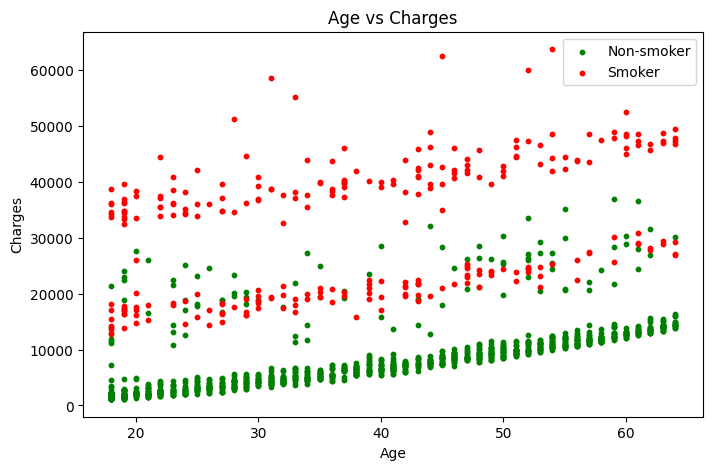

In [22]:
# Scatter plot: Age vs Charges (smokers vs non-smokers)
smokers = df[df['smoker'] == 'yes']
non_smokers = df[df['smoker'] == 'no']

plt.figure(figsize=(8, 5))
plt.scatter(non_smokers['age'], non_smokers['charges'], color='green', label='Non-smoker', s=10)
plt.scatter(smokers['age'], smokers['charges'], color='red', label='Smoker', s=10)
plt.xlabel('Age')
plt.ylabel('Charges')
plt.title('Age vs Charges')
plt.legend()
plt.show()

In [23]:
import pandas as pd
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.ensemble import RandomForestRegressor

full = pd.read_csv('Medical_insurance.csv')
full['smoker'] = full['smoker'].map({'yes':1,'no':0})
full['sex'] = full['sex'].map({'male':1,'female':0})
Xf = pd.get_dummies(full.drop('charges', axis=1), columns=['region'], drop_first=True)
yf = full['charges']

sk = SelectKBest(f_regression, k=3).fit(Xf, yf)
print(pd.DataFrame({'feature':Xf.columns,'F':sk.scores_,'p':sk.pvalues_}).sort_values('F', ascending=False))

rf_fs = RandomForestRegressor(n_estimators=100, random_state=42).fit(Xf, yf)
print(pd.Series(rf_fs.feature_importances_, index=Xf.columns).sort_values(ascending=False))

            feature            F              p
4            smoker  2177.614868  8.271436e-283
0               age   131.174013   4.886693e-29
2               bmi    54.709308   2.459086e-13
6  region_southeast     7.352531   6.782699e-03
3          children     6.206037   1.285213e-02
1               sex     4.399702   3.613272e-02
7  region_southwest     2.499121   1.141466e-01
5  region_northwest     2.130837   1.445970e-01
smoker              0.619903
bmi                 0.209889
age                 0.130213
children            0.019212
sex                 0.005763
region_northwest    0.005702
region_southeast    0.005186
region_southwest    0.004132
dtype: float64


# Train / Test Split

In [24]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

le = LabelEncoder()

encoded_col = ['smoker']
for x in encoded_col:
    df[x] = le.fit_transform(df[x])

In [25]:
# Splitting the data into training and test
X = df.drop('charges', axis=1)
y = df['charges']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Training set: 1070 rows
Testing set : 268 rows


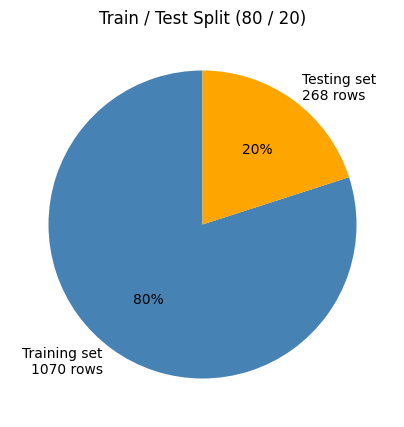

In [26]:
# Train / test split diagram
print('Training set:', X_train.shape[0], 'rows')
print('Testing set :', X_test.shape[0], 'rows')

sizes = [len(X_train), len(X_test)]
labels = [f'Training set\n{len(X_train)} rows', f'Testing set\n{len(X_test)} rows']

plt.figure(figsize=(5, 5))
plt.pie(sizes, labels=labels, autopct='%1.0f%%', colors=['steelblue', 'orange'], startangle=90)
plt.title('Train / Test Split (80 / 20)')
plt.show()

In [27]:
# Scaling the data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [28]:
# PCA (dimensionality reduction): does it help our models?
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.decomposition import PCA
pca = PCA().fit(X_train_scaled)
print('Explained variance:', pca.explained_variance_ratio_)

pca2 = PCA(n_components=2).fit(X_train_scaled)
Xtr_p, Xte_p = pca2.transform(X_train_scaled), pca2.transform(X_test_scaled)
for name, m in [('Linear Regression', LinearRegression()),
                ('Random Forest', RandomForestRegressor(n_estimators=100, random_state=42))]:
    m.fit(Xtr_p, y_train); p = m.predict(Xte_p)
    print(name, 'R2 =', round(r2_score(y_test, p),3), 'RMSE =', round(np.sqrt(mean_squared_error(y_test, p)),1))

Explained variance: [0.37683761 0.33248577 0.29067663]
Linear Regression R2 = 0.673 RMSE = 7119.8
Random Forest R2 = 0.854 RMSE = 4760.4


## Decision Tree (Regression)

In [29]:
dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)

DecisionTreeRegressor(random_state=42)

In [30]:
y_pred1 = dt_model.predict(X_test)

In [31]:
import numpy as np

# Compute metrics
dt_mse = mean_squared_error(y_test, y_pred1)
dt_rmse = np.sqrt(dt_mse)
dt_mae = mean_absolute_error(y_test, y_pred1)
dt_r2 = r2_score(y_test, y_pred1)

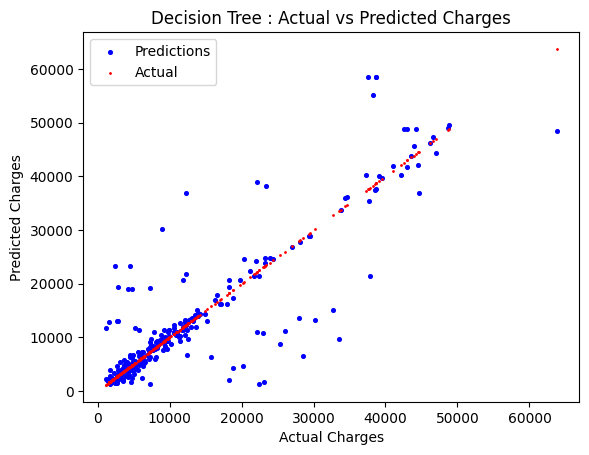

Mean Squared Error (MSE): 40185671.200175
Root Mean Squared Error (RMSE): 6339.216923262289
Mean Absolute Error (MAE): 3159.0007089552237
R-squared (R2) Score: 0.741152986135651


In [32]:
# Scatter plot of actual vs predicted values
plt.scatter(y_test, y_pred1, color='blue', label='Predictions', s=7)
plt.scatter(y_test, y_test, color='red', label='Actual',s=1)

plt.xlabel('Actual Charges')
plt.ylabel('Predicted Charges')
plt.title('Decision Tree : Actual vs Predicted Charges')
plt.legend()
plt.show()

# Printing metrics
print('Mean Squared Error (MSE):', dt_mse)
print('Root Mean Squared Error (RMSE):', dt_rmse)
print('Mean Absolute Error (MAE):', dt_mae)
print('R-squared (R2) Score:', dt_r2)

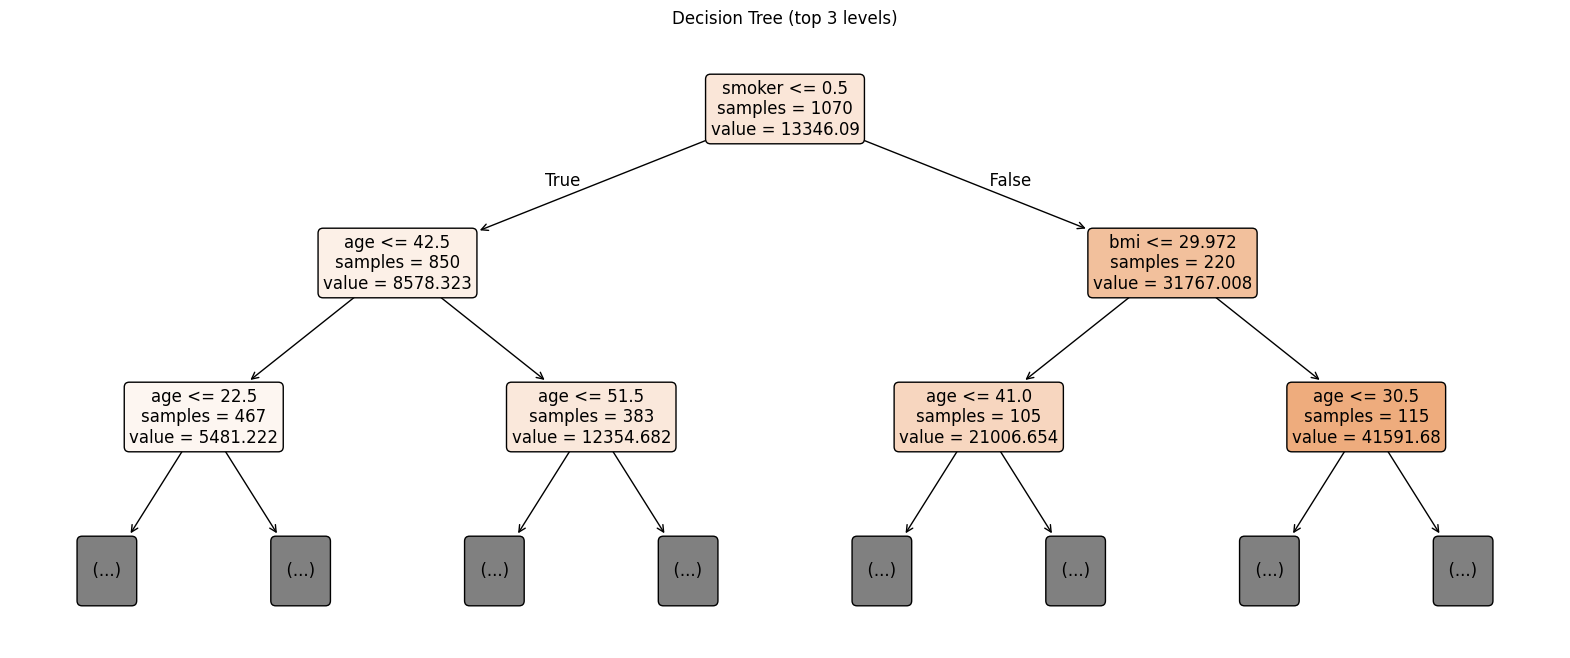

In [33]:
# Decision tree diagram (top 3 levels, the full tree is too big to read)
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 8))
plot_tree(dt_model, feature_names=list(X.columns), max_depth=2, filled=True, rounded=True, impurity=False, fontsize=12)
plt.title('Decision Tree (top 3 levels)')
plt.show()

## Decision Tree (ID3 Algorithm)

ID3 builds a decision tree using **entropy** and **information gain**. At every step it picks the question that splits the people into the most "pure" groups.

ID3 works with **categories**, not exact numbers, so we first group the charges into three classes:
- **Low**: under \$10,000
- **Medium**: \$10,000 to \$30,000
- **High**: over \$30,000

In scikit-learn, `DecisionTreeClassifier(criterion='entropy')` uses the ID3 way of choosing splits (information gain).

In [34]:
# ID3 needs categories, so group charges into Low / Medium / High
y_class = pd.cut(y, bins=[0, 10000, 30000, float('inf')], labels=['Low', 'Medium', 'High'])
print(y_class.value_counts())

# Same 80/20 split as before (same random_state, so the same people go to train and test)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X, y_class, test_size=0.2, random_state=42)

charges
Low       712
Medium    464
High      162
Name: count, dtype: int64


In [35]:
# ID3: decision tree that uses entropy / information gain to choose each split
id3_model = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)
id3_model.fit(X_train_c, y_train_c)

y_pred_id3 = id3_model.predict(X_test_c)

# Classification metrics
id3_acc = accuracy_score(y_test_c, y_pred_id3)
print('Accuracy :', round(id3_acc, 3))
print('Precision:', round(precision_score(y_test_c, y_pred_id3, average='weighted'), 3))
print('Recall   :', round(recall_score(y_test_c, y_pred_id3, average='weighted'), 3))
print('F1-score :', round(f1_score(y_test_c, y_pred_id3, average='weighted'), 3))

Accuracy : 0.914
Precision: 0.919
Recall   : 0.914
F1-score : 0.911


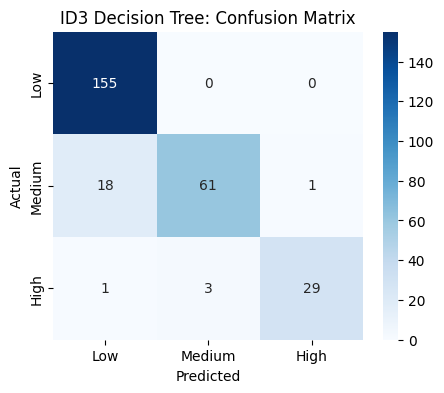

In [36]:
# Confusion matrix: rows = actual class, columns = predicted class
labels = ['Low', 'Medium', 'High']
cm = confusion_matrix(y_test_c, y_pred_id3, labels=labels)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('ID3 Decision Tree: Confusion Matrix')
plt.show()

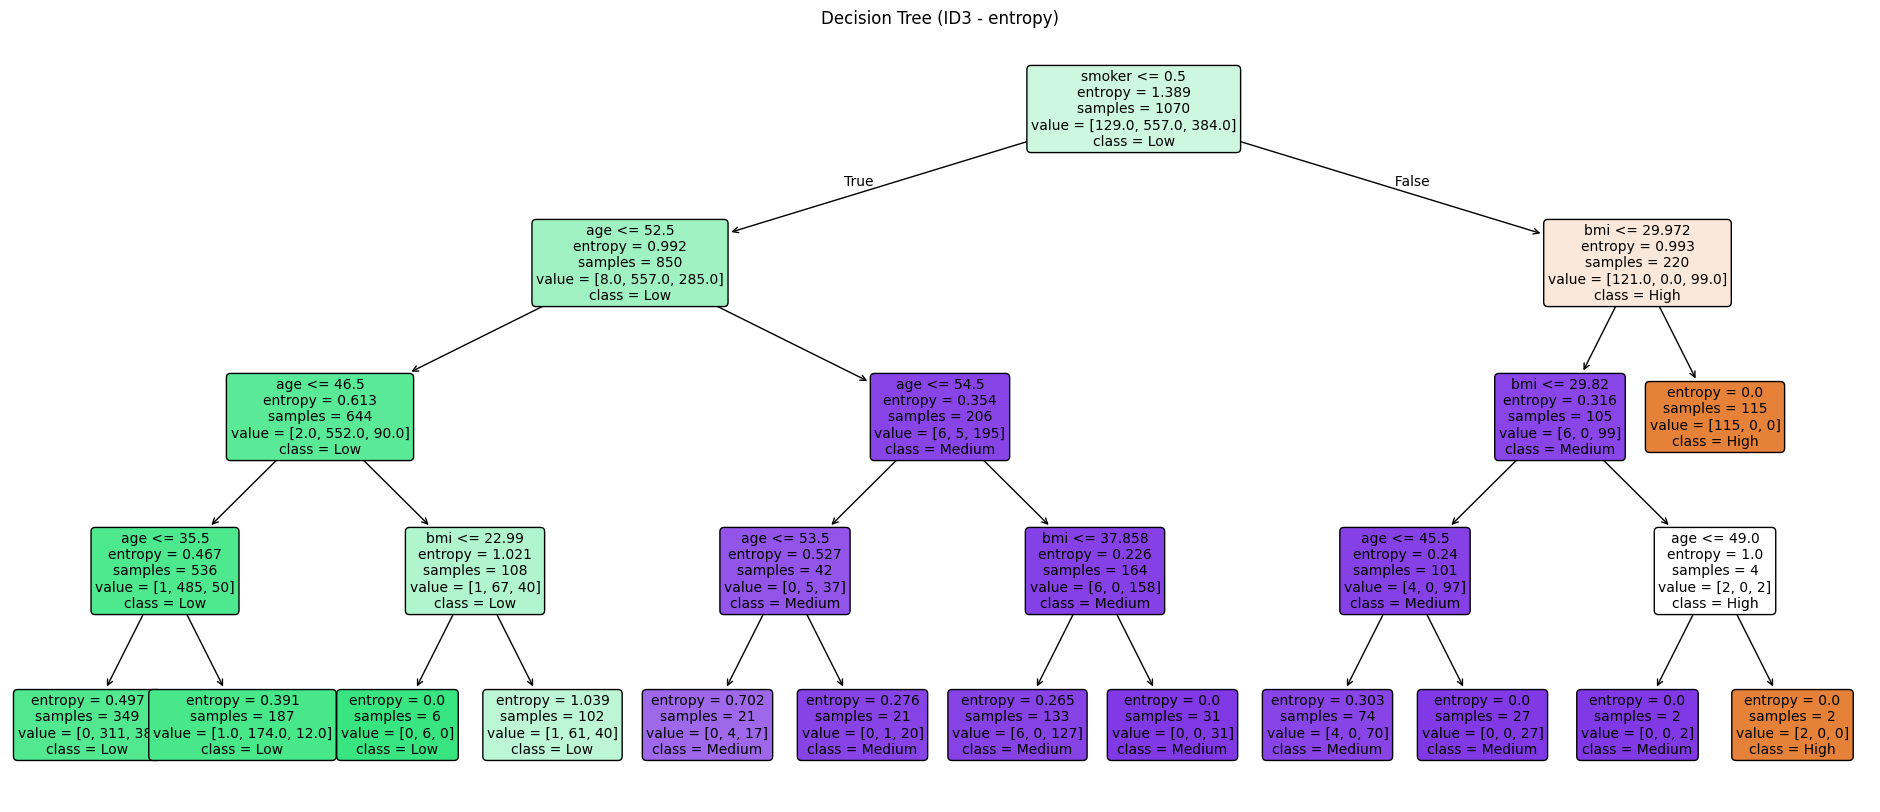

In [37]:
# ID3 decision tree diagram
plt.figure(figsize=(24, 10))
plot_tree(id3_model, feature_names=list(X.columns), class_names=list(id3_model.classes_), filled=True, rounded=True, fontsize=10)
plt.title('Decision Tree (ID3 - entropy)')
plt.show()

## Linear Regression

In [38]:

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

LinearRegression()

In [39]:
y_pred2 = lr_model.predict(X_test)

In [40]:
import numpy as np

# Compute metrics
lr_mse = mean_squared_error(y_test, y_pred2)
lr_rmse = np.sqrt(lr_mse)
lr_mae = mean_absolute_error(y_test, y_pred2)
lr_r2 = r2_score(y_test, y_pred2)

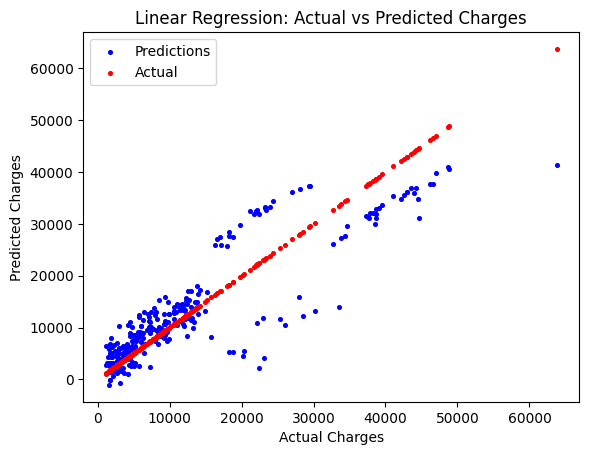

Mean Squared Error (MSE): 34512845.721840486
Root Mean Squared Error (RMSE): 5874.763460926787
Mean Absolute Error (MAE): 4260.560503057418
R-squared (R2) Score: 0.7776932227768668


In [41]:
import matplotlib.pyplot as plt

# Scatter plot of actual vs predicted values
plt.scatter(y_test, y_pred2, color='blue', label='Predictions', s=7)
plt.scatter(y_test, y_test, color='red', label='Actual',s=7)

plt.xlabel('Actual Charges')
plt.ylabel('Predicted Charges')
plt.title('Linear Regression: Actual vs Predicted Charges')
plt.legend()
plt.show()

# Printing metrics
print('Mean Squared Error (MSE):', lr_mse)
print('Root Mean Squared Error (RMSE):', lr_rmse)
print('Mean Absolute Error (MAE):', lr_mae)
print('R-squared (R2) Score:', lr_r2)


## Random Forest

A Random Forest builds **many decision trees** (here 100). Each tree learns from a random sample of the training data, and the forest **averages** all their predictions. Averaging many trees cancels out the mistakes a single tree makes.

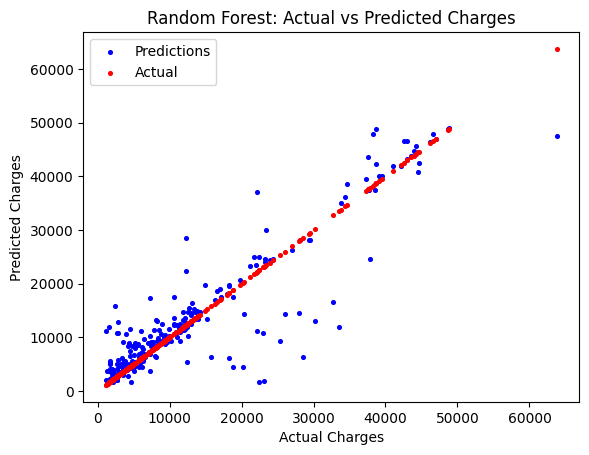

Mean Squared Error (MSE): 25732928.380385462
Root Mean Squared Error (RMSE): 5072.763386989922
Mean Absolute Error (MAE): 2766.9597737781346
R-squared (R2) Score: 0.8342470967806324


In [42]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

y_pred3 = rf_model.predict(X_test)

# Compute metrics
rf_mse = mean_squared_error(y_test, y_pred3)
rf_rmse = np.sqrt(rf_mse)
rf_mae = mean_absolute_error(y_test, y_pred3)
rf_r2 = r2_score(y_test, y_pred3)

# Scatter plot of actual vs predicted values
plt.scatter(y_test, y_pred3, color='blue', label='Predictions', s=7)
plt.scatter(y_test, y_test, color='red', label='Actual', s=7)
plt.xlabel('Actual Charges')
plt.ylabel('Predicted Charges')
plt.title('Random Forest: Actual vs Predicted Charges')
plt.legend()
plt.show()

# Printing metrics
print('Mean Squared Error (MSE):', rf_mse)
print('Root Mean Squared Error (RMSE):', rf_rmse)
print('Mean Absolute Error (MAE):', rf_mae)
print('R-squared (R2) Score:', rf_r2)

# Evaluation Metrics

The table below compares the three regression models on the test data. Lower MSE, RMSE and MAE is better. A higher R2 score (closer to 1) is better.

The ID3 tree predicts classes (Low / Medium / High) instead of exact charges, so it is scored with accuracy, precision, recall and F1 in its own section above.

In [43]:
# Evaluation metrics: compare the regression models side by side
results = pd.DataFrame({
    'Model': ['Decision Tree', 'Linear Regression', 'Random Forest'],
    'MSE': [dt_mse, lr_mse, rf_mse],
    'RMSE': [dt_rmse, lr_rmse, rf_rmse],
    'MAE': [dt_mae, lr_mae, rf_mae],
    'R2 Score': [dt_r2, lr_r2, rf_r2]
})

# Show numbers with commas instead of scientific notation (like 4.0e+07)
pd.options.display.float_format = '{:,.3f}'.format
results

,Model,MSE,RMSE,MAE,R2 Score
0,Decision Tree,"40,185,671.200","6,339.217","3,159.001",0.741
1,Linear Regression,"34,512,845.722","5,874.763","4,260.561",0.778
2,Random Forest,"25,732,928.380","5,072.763","2,766.960",0.834
